In [1]:
import os, json, time, random, platform
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Visible GPU count:", torch.cuda.device_count())

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


Python: 3.13.16
NumPy: 2.1.3
Pandas: 2.3.3
PyTorch: 2.11.0+cu130
CUDA available: True
Device: cuda:0
GPU: Tesla T4
Visible GPU count: 2


In [2]:
DATA_DIR = Path(
    "/kaggle/input/datasets/drrajgauravmishra/"
    "spatiotemporal-gnn-kaggle-data"
)
OUTPUT_DIR = Path("/kaggle/working/lstm_baseline_results")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

for filename in [
    "training_annual.npz", "validation_annual.npz",
    "testing_annual.npz", "annual_forecasting_metadata.json"
]:
    if not (DATA_DIR / filename).exists():
        raise FileNotFoundError(DATA_DIR / filename)

train_npz = np.load(DATA_DIR / "training_annual.npz")
val_npz = np.load(DATA_DIR / "validation_annual.npz")
test_npz = np.load(DATA_DIR / "testing_annual.npz")
with open(DATA_DIR / "annual_forecasting_metadata.json") as f:
    metadata = json.load(f)

X_train_np, Y_train_np, M_train_np = train_npz["X"], train_npz["Y"], train_npz["Y_mask"]
X_val_np, Y_val_np, M_val_np = val_npz["X"], val_npz["Y"], val_npz["Y_mask"]
X_test_np, Y_test_np, M_test_np = test_npz["X"], test_npz["Y"], test_npz["Y_mask"]

print("Train:", X_train_np.shape, Y_train_np.shape, M_train_np.shape)
print("Validation:", X_val_np.shape, Y_val_np.shape, M_val_np.shape)
print("Test:", X_test_np.shape, Y_test_np.shape, M_test_np.shape)
print("Train target years:", train_npz["target_years"])
print("Validation target years:", val_npz["target_years"])
print("Test target years:", test_npz["target_years"])
print("Input features:", metadata["input_features"])
print("Targets:", metadata["target_variables"])


Train: (8, 10, 5040, 4) (8, 5040, 2) (8, 5040, 2)
Validation: (6, 10, 5040, 4) (6, 5040, 2) (6, 5040, 2)
Test: (2, 10, 5040, 4) (2, 5040, 2) (2, 5040, 2)
Train target years: [2010 2011 2012 2013 2014 2015 2016 2017]
Validation target years: [2018 2019 2020 2021 2022 2023]
Test target years: [2024 2025]
Input features: ['Normalized rainfall', 'Normalized maximum temperature', 'Rainfall missingness indicator', 'Temperature missingness indicator']
Targets: ['Rainfall (mm/day)', 'Maximum temperature (degree_Celsius)']


In [3]:
assert X_train_np.shape[1:] == (10, 5040, 4)
assert X_val_np.shape[1:] == (10, 5040, 4)
assert X_test_np.shape[1:] == (10, 5040, 4)
assert Y_train_np.shape[1:] == (5040, 2)
assert Y_val_np.shape[1:] == (5040, 2)
assert Y_test_np.shape[1:] == (5040, 2)
assert M_train_np.shape == Y_train_np.shape
assert M_val_np.shape == Y_val_np.shape
assert M_test_np.shape == Y_test_np.shape
assert np.isfinite(X_train_np).all()
assert np.isfinite(X_val_np).all()
assert np.isfinite(X_test_np).all()
assert train_npz["target_years"].tolist() == list(range(2010, 2018))
assert val_npz["target_years"].tolist() == list(range(2018, 2024))
assert test_npz["target_years"].tolist() == [2024, 2025]
print("Data integrity checks passed.")

# Target normalization is fitted on observed training targets only.
target_mean = np.zeros(2, dtype=np.float32)
target_std = np.zeros(2, dtype=np.float32)
for v in range(2):
    values = Y_train_np[:, :, v][M_train_np[:, :, v]]
    target_mean[v] = values.mean()
    target_std[v] = values.std()
    if target_std[v] == 0:
        raise ValueError(f"Zero target standard deviation for variable {v}")

print("Target means:", target_mean)
print("Target standard deviations:", target_std)

def normalize_y(y):
    return (y - target_mean.reshape(1, 1, 2)) / target_std.reshape(1, 1, 2)

X_train = torch.from_numpy(X_train_np.astype(np.float32)).to(device)
X_val = torch.from_numpy(X_val_np.astype(np.float32)).to(device)
X_test = torch.from_numpy(X_test_np.astype(np.float32)).to(device)

Y_train = torch.from_numpy(normalize_y(Y_train_np).astype(np.float32)).to(device)
Y_val = torch.from_numpy(normalize_y(Y_val_np).astype(np.float32)).to(device)
Y_test = torch.from_numpy(normalize_y(Y_test_np).astype(np.float32)).to(device)

M_train = torch.from_numpy(M_train_np.astype(bool)).to(device)
M_val = torch.from_numpy(M_val_np.astype(bool)).to(device)
M_test = torch.from_numpy(M_test_np.astype(bool)).to(device)

print("Tensor shapes:", tuple(X_train.shape), tuple(Y_train.shape),
      tuple(X_val.shape), tuple(Y_val.shape), tuple(X_test.shape), tuple(Y_test.shape))
print("Valid training targets:", M_train_np.sum(axis=(0, 1)))
print("Valid validation targets:", M_val_np.sum(axis=(0, 1)))
print("Valid test targets:", M_test_np.sum(axis=(0, 1)))


Data integrity checks passed.
Target means: [ 3.0588877 31.36195  ]
Target standard deviations: [2.156659 2.990062]
Tensor shapes: (8, 10, 5040, 4) (8, 5040, 2) (6, 10, 5040, 4) (6, 5040, 2) (2, 10, 5040, 4) (2, 5040, 2)
Valid training targets: [37888 35563]
Valid validation targets: [28416 26627]
Valid test targets: [9472 8952]


In [4]:
class LSTMBaseline(nn.Module):
    # Each node's 10-year temporal sequence is processed independently.
    def __init__(self, input_dim=4, hidden_dim=128, num_layers=1,
                 output_dim=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        batch_size, time_steps, num_nodes, num_features = x.shape
        x = x.permute(0, 2, 1, 3).reshape(
            batch_size * num_nodes, time_steps, num_features
        )
        _, (hidden, cell) = self.lstm(x)
        output = self.fc(self.dropout(hidden[-1]))
        return output.reshape(batch_size, num_nodes, 2)

set_seed(42)
check_model = LSTMBaseline(hidden_dim=128).to(device)
with torch.no_grad():
    check_output = check_model(X_train[:1])
print("Input:", tuple(X_train[:1].shape))
print("Output:", tuple(check_output.shape))
print("Trainable parameters:", sum(p.numel() for p in check_model.parameters()))
assert check_output.shape == (1, 5040, 2)
print("Architecture verification passed.")


Input: (1, 10, 5040, 4)
Output: (1, 5040, 2)
Trainable parameters: 68866
Architecture verification passed.


In [5]:
def masked_mse(pred, target, mask):
    # Select only valid positions before calculating errors
    valid_pred = pred[mask]
    valid_target = target[mask]

    return torch.mean((valid_pred - valid_target) ** 2)

def calculate_metrics(y, p):
    mae = float(np.mean(np.abs(y - p)))
    rmse = float(np.sqrt(np.mean((y - p) ** 2)))
    ss_res = float(np.sum((y - p) ** 2))
    ss_tot = float(np.sum((y - np.mean(y)) ** 2))
    r2 = float(1 - ss_res / ss_tot) if ss_tot > 0 else float("nan")
    return mae, rmse, r2

def evaluate_model(model, X, Y_norm, mask):
    model.eval()
    with torch.no_grad():
        pred_norm = model(X).cpu().numpy()

    pred = pred_norm * target_std.reshape(1, 1, 2) + target_mean.reshape(1, 1, 2)
    y = Y_norm.cpu().numpy() * target_std.reshape(1, 1, 2) + target_mean.reshape(1, 1, 2)
    valid_mask = mask.cpu().numpy()

    rows = []
    for v, name in enumerate(["Rainfall", "Maximum Temperature"]):
        valid = valid_mask[:, :, v]
        mae, rmse, r2 = calculate_metrics(y[:, :, v][valid], pred[:, :, v][valid])
        rows.append({
            "Variable": name, "MAE": mae, "RMSE": rmse,
            "R2": r2, "Valid_Count": int(valid.sum())
        })
    return pd.DataFrame(rows), pred


In [6]:
def train_lstm(model, seed, max_epochs, learning_rate=0.001,
                patience=30):
    # Full-batch training, matching the revised GRU experiment.
    set_seed(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    no_improvement = 0
    history = {"train_loss": [], "validation_loss": []}
    start = time.time()

    for epoch in range(1, max_epochs + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        pred_train = model(X_train)
        loss_train = masked_mse(pred_train, Y_train, M_train)
        loss_train.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            pred_val = model(X_val)
            loss_val = masked_mse(pred_val, Y_val, M_val)

        train_value = float(loss_train.item())
        val_value = float(loss_val.item())
        history["train_loss"].append(train_value)
        history["validation_loss"].append(val_value)

        if val_value < best_val_loss:
            best_val_loss = val_value
            best_epoch = epoch
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            no_improvement = 0
        else:
            no_improvement += 1

        if epoch == 1 or epoch % 50 == 0:
            print(f"Seed {seed} | Epoch {epoch}/{max_epochs} | "
                  f"Train {train_value:.6f} | Val {val_value:.6f}")

        if no_improvement >= patience:
            print(f"Early stopping at {epoch}; best epoch: {best_epoch}")
            break

    if best_state is None:
        raise RuntimeError("No best model checkpoint was created.")

    model.load_state_dict(best_state)
    model.to(device)

    return model, {
        "seed": seed,
        "max_epochs": max_epochs,
        "epochs_trained": len(history["train_loss"]),
        "best_epoch": best_epoch,
        "best_validation_loss": best_val_loss,
        "training_time_seconds": time.time() - start,
        "history": history
    }


In [7]:

# LSTM numerical stability diagnostic

set_seed(42)

diagnostic_model = LSTMBaseline(
    input_dim=4,
    hidden_dim=64,
    num_layers=1,
    output_dim=2,
    dropout=0.2
).to(device)

print("========== INPUT CHECK ==========")
print("X_train finite:", torch.isfinite(X_train).all().item())
print("X_val finite:", torch.isfinite(X_val).all().item())

print("\n========== TARGET CHECK ==========")
print("Y_train finite at valid positions:",
      torch.isfinite(Y_train[M_train]).all().item())
print("Y_val finite at valid positions:",
      torch.isfinite(Y_val[M_val]).all().item())

print("\n========== MODEL FORWARD CHECK ==========")

with torch.no_grad():
    train_pred = diagnostic_model(X_train)
    val_pred = diagnostic_model(X_val)

print("Training prediction finite:",
      torch.isfinite(train_pred).all().item())
print("Validation prediction finite:",
      torch.isfinite(val_pred).all().item())

print("\n========== INITIAL LOSS CHECK ==========")

initial_train_loss = masked_mse(
    train_pred, Y_train, M_train
)

initial_val_loss = masked_mse(
    val_pred, Y_val, M_val
)

print("Initial training loss:", initial_train_loss.item())
print("Initial validation loss:", initial_val_loss.item())

print("\n========== TARGET NORMALIZATION ==========")
print("Target means:", target_mean)
print("Target standard deviations:", target_std)


========== INPUT CHECK ==========
X_train finite: True
X_val finite: True

========== TARGET CHECK ==========
Y_train finite at valid positions: True
Y_val finite at valid positions: True

========== MODEL FORWARD CHECK ==========
Training prediction finite: True
Validation prediction finite: True

========== INITIAL LOSS CHECK ==========
Initial training loss: 0.9888220429420471
Initial validation loss: 1.0266430377960205

========== TARGET NORMALIZATION ==========
Target means: [ 3.0588877 31.36195  ]
Target standard deviations: [2.156659 2.990062]


In [8]:
# ============================================
# LSTM GRADIENT STABILITY CHECK
# ============================================

set_seed(42)

diagnostic_model = LSTMBaseline(
    input_dim=4,
    hidden_dim=64,
    num_layers=1,
    output_dim=2,
    dropout=0.2
).to(device)

diagnostic_optimizer = torch.optim.Adam(
    diagnostic_model.parameters(),
    lr=0.001
)

diagnostic_model.train()

diagnostic_optimizer.zero_grad()

predictions = diagnostic_model(X_train)
loss = masked_mse(predictions, Y_train, M_train)

loss.backward()

gradient_norms = []
non_finite_gradients = 0

for name, parameter in diagnostic_model.named_parameters():
    if parameter.grad is not None:
        grad = parameter.grad

        if torch.isfinite(grad).all():
            gradient_norms.append(grad.norm().item())
        else:
            non_finite_gradients += 1

print("========== GRADIENT CHECK ==========")
print("Training loss:", loss.item())
print("Non-finite gradient tensors:", non_finite_gradients)

if gradient_norms:
    print("Maximum gradient norm:", max(gradient_norms))
    print("Minimum gradient norm:", min(gradient_norms))
    print("Total gradient norm:",
          torch.nn.utils.clip_grad_norm_(
              diagnostic_model.parameters(),
              max_norm=float("inf")
          ).item())

========== GRADIENT CHECK ==========
Training loss: 0.9888220429420471
Non-finite gradient tensors: 0
Maximum gradient norm: 0.3781295120716095
Minimum gradient norm: 0.043551474809646606
Total gradient norm: 0.5444486737251282


In [9]:
# Original paper candidates and optimizer settings.
HIDDEN_SIZES = [64, 128]
EPOCH_OPTIONS = [300, 500]
LEARNING_RATE = 0.001
SEEDS = [42, 123, 2023]
PATIENCE = 30
DROPOUT = 0.2  # Retained to match the revised GRU baseline implementation.

search_rows = []
search_histories = {}

for hidden_size in HIDDEN_SIZES:
    for max_epochs in EPOCH_OPTIONS:
        for seed in SEEDS:
            print("\\n" + "=" * 72)
            print(f"LSTM | hidden={hidden_size} | max_epochs={max_epochs} | seed={seed}")
            print("=" * 72)

            set_seed(seed)  # Seed before model initialization.
            model = LSTMBaseline(
                input_dim=4, hidden_dim=hidden_size,
                num_layers=1, output_dim=2, dropout=DROPOUT
            ).to(device)

            model, result = train_lstm(
                model, seed, max_epochs,
                learning_rate=LEARNING_RATE, patience=PATIENCE
            )

            search_rows.append({
                "hidden_size": hidden_size,
                "max_epochs": max_epochs,
                "seed": seed,
                "best_validation_loss": result["best_validation_loss"],
                "best_epoch": result["best_epoch"],
                "epochs_trained": result["epochs_trained"],
                "training_time_seconds": result["training_time_seconds"]
            })
            search_histories[(hidden_size, max_epochs, seed)] = result["history"]

            checkpoint = CHECKPOINT_DIR / f"lstm_h{hidden_size}_e{max_epochs}_seed{seed}.pt"
            torch.save({
                "model_state_dict": model.state_dict(),
                "hidden_size": hidden_size,
                "max_epochs": max_epochs,
                "seed": seed,
                "best_epoch": result["best_epoch"],
                "best_validation_loss": result["best_validation_loss"],
                "target_mean": target_mean,
                "target_std": target_std
            }, checkpoint)

search_df = pd.DataFrame(search_rows)
search_summary = (
    search_df.groupby(["hidden_size", "max_epochs"], as_index=False)
    .agg(
        mean_validation_loss=("best_validation_loss", "mean"),
        std_validation_loss=("best_validation_loss", "std"),
        mean_best_epoch=("best_epoch", "mean"),
        mean_training_time=("training_time_seconds", "mean")
    )
    .sort_values(
        ["mean_validation_loss", "max_epochs", "hidden_size"],
        ascending=[True, True, True]
    )
    .reset_index(drop=True)
)

print("\\nHYPERPARAMETER SEARCH SUMMARY")
print(search_summary.to_string(index=False))

search_df.to_csv(OUTPUT_DIR / "lstm_hyperparameter_search_runs.csv", index=False)
search_summary.to_csv(OUTPUT_DIR / "lstm_hyperparameter_search_summary.csv", index=False)


\n========================================================================
LSTM | hidden=64 | max_epochs=300 | seed=42
Seed 42 | Epoch 1/300 | Train 0.988822 | Val 1.010500
Seed 42 | Epoch 50/300 | Train 0.229908 | Val 0.200738
Seed 42 | Epoch 100/300 | Train 0.183137 | Val 0.141293
Seed 42 | Epoch 150/300 | Train 0.172295 | Val 0.128291
Seed 42 | Epoch 200/300 | Train 0.168391 | Val 0.125914
Seed 42 | Epoch 250/300 | Train 0.165667 | Val 0.125559
Early stopping at 287; best epoch: 257
\n========================================================================
LSTM | hidden=64 | max_epochs=300 | seed=123
Seed 123 | Epoch 1/300 | Train 1.026038 | Val 1.071135
Seed 123 | Epoch 50/300 | Train 0.242429 | Val 0.220469
Seed 123 | Epoch 100/300 | Train 0.180567 | Val 0.138761
Seed 123 | Epoch 150/300 | Train 0.171575 | Val 0.128876
Seed 123 | Epoch 200/300 | Train 0.167470 | Val 0.126741
Seed 123 | Epoch 250/300 | Train 0.164970 | Val 0.126513
Early stopping at 267; best epoch: 237
\n=========

In [10]:
# Lowest mean validation loss wins. In a tie, prefer fewer maximum epochs,
# then the smaller hidden size.
best = search_summary.iloc[0]
SELECTED_HIDDEN = int(best["hidden_size"])
SELECTED_EPOCHS = int(best["max_epochs"])

selected_config = {
    "model": "Node-wise LSTM raw-feature baseline",
    "hidden_size": SELECTED_HIDDEN,
    "max_epochs": SELECTED_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "dropout": DROPOUT,
    "patience": PATIENCE,
    "seeds": SEEDS,
    "selection_metric": "Mean validation masked MSE",
    "mean_validation_loss": float(best["mean_validation_loss"])
}

print(json.dumps(selected_config, indent=2))
with open(OUTPUT_DIR / "lstm_selected_configuration.json", "w") as f:
    json.dump(selected_config, f, indent=2)


{
  "model": "Node-wise LSTM raw-feature baseline",
  "hidden_size": 128,
  "max_epochs": 300,
  "learning_rate": 0.001,
  "dropout": 0.2,
  "patience": 30,
  "seeds": [
    42,
    123,
    2023
  ],
  "selection_metric": "Mean validation masked MSE",
  "mean_validation_loss": 0.12205448498328526
}


In [11]:
# The selected configuration is fixed before test evaluation.
# Each seed is retrained and evaluated once on the held-out 2024–2025 test set.
test_rows = []
final_predictions = {}

for seed in SEEDS:
    print("\\n" + "=" * 72)
    print(f"FINAL LSTM | hidden={SELECTED_HIDDEN} | epochs={SELECTED_EPOCHS} | seed={seed}")
    print("=" * 72)

    set_seed(seed)
    model = LSTMBaseline(
        input_dim=4, hidden_dim=SELECTED_HIDDEN,
        num_layers=1, output_dim=2, dropout=DROPOUT
    ).to(device)

    model, result = train_lstm(
        model, seed, SELECTED_EPOCHS,
        learning_rate=LEARNING_RATE, patience=PATIENCE
    )

    # Save final selected checkpoint.
    torch.save({
        "model_state_dict": model.state_dict(),
        "selected_config": selected_config,
        "seed": seed,
        "best_epoch": result["best_epoch"],
        "best_validation_loss": result["best_validation_loss"],
        "target_mean": target_mean,
        "target_std": target_std
    }, CHECKPOINT_DIR / f"lstm_final_seed_{seed}.pt")

    metrics_df, predictions = evaluate_model(model, X_test, Y_test, M_test)
    final_predictions[seed] = predictions

    for _, row in metrics_df.iterrows():
        test_rows.append({
            "Seed": seed,
            "Variable": row["Variable"],
            "MAE": row["MAE"],
            "RMSE": row["RMSE"],
            "R2": row["R2"],
            "Valid_Count": row["Valid_Count"],
            "Best_Epoch": result["best_epoch"],
            "Best_Validation_Loss": result["best_validation_loss"]
        })

    print(metrics_df.to_string(index=False))

test_results = pd.DataFrame(test_rows)
print("\\nTEST RESULTS BY SEED")
print(test_results.to_string(index=False))
test_results.to_csv(OUTPUT_DIR / "lstm_test_results_by_seed.csv", index=False)


\n========================================================================
FINAL LSTM | hidden=128 | epochs=300 | seed=42
Seed 42 | Epoch 1/300 | Train 1.006342 | Val 1.016666
Seed 42 | Epoch 50/300 | Train 0.194671 | Val 0.152378
Seed 42 | Epoch 100/300 | Train 0.167350 | Val 0.125466
Seed 42 | Epoch 150/300 | Train 0.162523 | Val 0.121501
Early stopping at 185; best epoch: 155
           Variable      MAE     RMSE       R2  Valid_Count
           Rainfall 0.601795 0.838676 0.844061         9472
Maximum Temperature 0.512785 0.696898 0.935506         8952
\n========================================================================
FINAL LSTM | hidden=128 | epochs=300 | seed=123
Seed 123 | Epoch 1/300 | Train 0.993754 | Val 0.992801
Seed 123 | Epoch 50/300 | Train 0.188976 | Val 0.154037
Seed 123 | Epoch 100/300 | Train 0.167406 | Val 0.123747
Seed 123 | Epoch 150/300 | Train 0.162634 | Val 0.123584
Early stopping at 161; best epoch: 131
           Variable      MAE     RMSE       R2  Val

In [12]:
test_summary = (
    test_results.groupby("Variable", as_index=False)
    .agg(
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        R2_mean=("R2", "mean"),
        R2_std=("R2", "std"),
        Valid_Count=("Valid_Count", "first")
    )
)

print("FINAL LSTM TEST SUMMARY – 2024–2025")
print(test_summary.to_string(index=False))
test_summary.to_csv(OUTPUT_DIR / "lstm_test_summary.csv", index=False)

print("\\nSaved files:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(path)


FINAL LSTM TEST SUMMARY – 2024–2025
           Variable  MAE_mean  MAE_std  RMSE_mean  RMSE_std  R2_mean   R2_std  Valid_Count
Maximum Temperature  0.509880 0.002620   0.694786  0.002841 0.935896 0.000524         8952
           Rainfall  0.603008 0.003218   0.839750  0.003624 0.843659 0.001350         9472
\nSaved files:
/kaggle/working/lstm_baseline_results/checkpoints/lstm_final_seed_123.pt
/kaggle/working/lstm_baseline_results/checkpoints/lstm_final_seed_2023.pt
/kaggle/working/lstm_baseline_results/checkpoints/lstm_final_seed_42.pt
/kaggle/working/lstm_baseline_results/checkpoints/lstm_h128_e300_seed123.pt
/kaggle/working/lstm_baseline_results/checkpoints/lstm_h128_e300_seed2023.pt
/kaggle/working/lstm_baseline_results/checkpoints/lstm_h128_e300_seed42.pt
/kaggle/working/lstm_baseline_results/checkpoints/lstm_h128_e500_seed123.pt
/kaggle/working/lstm_baseline_results/checkpoints/lstm_h128_e500_seed2023.pt
/kaggle/working/lstm_baseline_results/checkpoints/lstm_h128_e500_seed42.pt
/

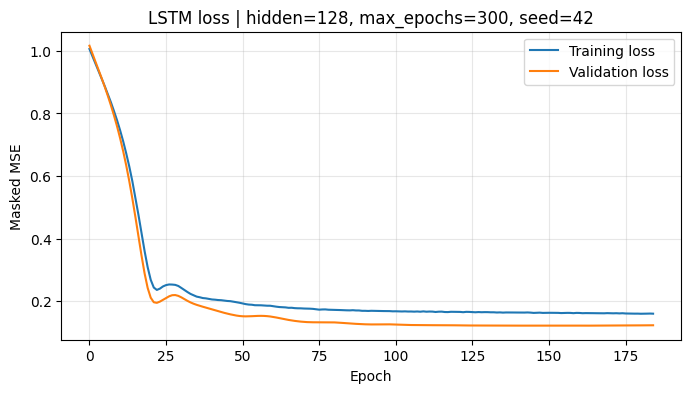

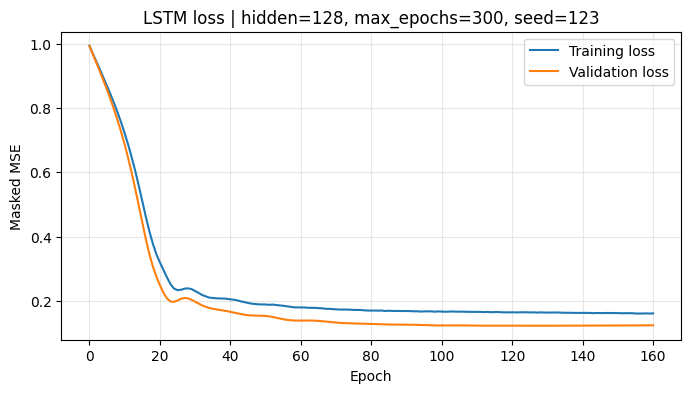

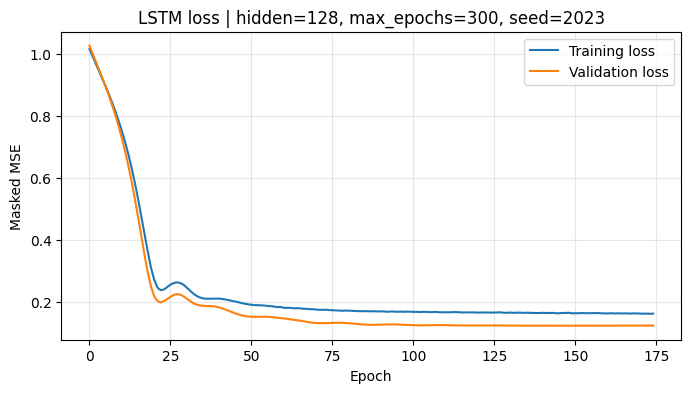

In [13]:
import matplotlib.pyplot as plt

for seed in SEEDS:
    history = search_histories[(SELECTED_HIDDEN, SELECTED_EPOCHS, seed)]
    plt.figure(figsize=(8, 4))
    plt.plot(history["train_loss"], label="Training loss")
    plt.plot(history["validation_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Masked MSE")
    plt.title(f"LSTM loss | hidden={SELECTED_HIDDEN}, max_epochs={SELECTED_EPOCHS}, seed={seed}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()
